# XGBoost inverse model: reactor conditions from polymer microstructure

Predicts four reactor conditions of ethylene/1-octene copolymerization (P, [Al]/[Ti], C8 preload and reaction time) from three microstructural descriptors extracted from GPC curves (`LogM_Mean`, `WF_Max`, `SCB_Mean`), using KNN-based data augmentation and an XGBoost regressor.

The notebook has three blocks:

1. **Libraries and data loading**: imports, settings and input files.
2. **Data preprocessing and modeling**: train/test split, KNN augmentation, training, evaluation, model saving, bootstrap prediction intervals and GPC preprocessing. Everything is saved to `results/`.
3. **Figures**: independent of Block 2 in memory. It reads the saved model and data from `results/` and writes the figures to `figures/`, one folder per figure type.

**How to run:** place this notebook in the same folder as `xgbnew.xlsx` and `Dados_tratados_2.xlsx`.
First run: Block 1 → Block 2 → Block 3. To regenerate only the figures: Block 1 → Block 3.

```
project_folder/
├── xgbnew.xlsx, Dados_tratados_2.xlsx
├── results/
│   ├── models/        xgboost_scenario_1.pkl, xgboost_scenario_2.pkl
│   ├── data/          train/test split, augmented training sets, processed GPC data
│   ├── uncertainty/   prediction_intervals.csv, interval_metrics.csv
│   └── model_metrics.csv
└── figures/
    ├── 01_model_fit/
    ├── 02_target_distributions/
    ├── 03_augmented_data/
    ├── 04_targets_vs_microstructure/
    ├── 05_gpc_mwd/
    ├── 06_gpc_scb/
    └── 07_prediction_intervals/
```

Tested with Python 3.12, pandas 3.0, scikit-learn 1.8, xgboost 3.4, matplotlib 3.10 and seaborn 0.13.

---
# 1. Libraries and data loading

### 1.1 Libraries

In [1]:
# --- Utilities ---
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import display

# --- Modeling ---
import xgboost as xgb
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_percentage_error, r2_score
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# --- Plotting ---
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

### 1.2 Settings
Paths, column names, output files and global parameters. Change things here only.

In [2]:
# Folder containing this notebook and the input files
BASE_DIR = Path.cwd()

# --- Input files ---
FILE_FULL = BASE_DIR / 'xgbnew.xlsx'            # sheet 'Completo': one row per experimental run
FILE_GPC  = BASE_DIR / 'Dados_tratados_2.xlsx'  # raw GPC curves

# --- Output folders (created automatically) ---
RESULTS_DIR     = BASE_DIR / 'results'
MODELS_DIR      = RESULTS_DIR / 'models'
DATA_DIR        = RESULTS_DIR / 'data'
UNCERTAINTY_DIR = RESULTS_DIR / 'uncertainty'
FIGURES_DIR     = BASE_DIR / 'figures'
for folder in [MODELS_DIR, DATA_DIR, UNCERTAINTY_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# --- Files written by Block 2 and read by Block 3 ---
FILE_TEST_REAL     = DATA_DIR / 'test_real_half.csv'          # real test set (never augmented)
FILE_TRAIN_REAL    = DATA_DIR / 'train_real_rest.csv'         # real training set (augmentation base)
FILE_TRAIN_AUG_S1  = DATA_DIR / 'train_augmented_scenario_1.csv'
FILE_TRAIN_AUG_S2  = DATA_DIR / 'train_augmented_scenario_2.csv'
FILE_GPC_CLEAN     = DATA_DIR / 'gpc_processed.csv'
FILE_MODEL_S1      = MODELS_DIR / 'xgboost_scenario_1.pkl'
FILE_MODEL_S2      = MODELS_DIR / 'xgboost_scenario_2.pkl'    # model reported in the paper
FILE_METRICS       = RESULTS_DIR / 'model_metrics.csv'
FILE_PI            = UNCERTAINTY_DIR / 'prediction_intervals.csv'
FILE_PI_METRICS    = UNCERTAINTY_DIR / 'interval_metrics.csv'

# --- Model columns ---
ID_COL   = 'Dataframe'
FEATURES = ['LogM_Mean', 'WF_Max', 'SCB_Mean']
TARGETS  = ['P (psi)', '[Al]/[Ti]', 'C8 preload (g)', 'Reaction time (min)']

# --- GPC columns ---
GPC_LOGM = 'LogM conventional'
GPC_WF   = 'Weight fraction / LogM'
GPC_SCB  = 'SCB / 1000 total carbons SCB'

# --- Global parameters ---
RANDOM_STATE = 42
N_BOOTSTRAP  = 500     # bootstrap models for the prediction intervals
Z_95         = 1.96    # normal quantile for a 95% interval

### 1.3 Data loading

In [3]:
def standardize_columns(df):
    # Strip column names, rename 'Run lentgh (min)' -> 'Reaction time (min)' and fix letter case
    df = df.copy()
    df.columns = df.columns.str.strip()
    df = df.rename(columns={'Run lentgh (min)': 'Reaction time (min)'})

    canonical = {c.lower(): c for c in FEATURES + TARGETS + [ID_COL]}
    df = df.rename(columns={c: canonical[c.lower()] for c in df.columns if c.lower() in canonical})

    if ID_COL in df.columns:
        df[ID_COL] = df[ID_COL].astype(str).str.strip()
    return df


print('📂 Loading data...')
df_full    = standardize_columns(pd.read_excel(FILE_FULL, sheet_name='Completo'))
df_gpc_raw = standardize_columns(pd.read_excel(FILE_GPC))

# --- Column check ---
datasets = {
    'Full':    (df_full,    [ID_COL] + FEATURES + TARGETS),
    'GPC raw': (df_gpc_raw, [GPC_LOGM, GPC_WF, GPC_SCB] + TARGETS),
}
for name, (df, columns) in datasets.items():
    missing = [c for c in columns if c not in df.columns]
    status = '✅' if not missing else f'❌ missing columns: {missing}'
    print(f'   {name:<8} {df.shape[0]:>7} rows  {status}')

duplicated_ids = df_full[ID_COL][df_full[ID_COL].duplicated()].tolist()
if duplicated_ids:
    print(f'🚨 Duplicated IDs in the full dataset: {duplicated_ids}')

📂 Loading data...
   Full         111 rows  ✅
   GPC raw   107000 rows  ✅


---
# 2. Data preprocessing and modeling

### 2.1 Train/test split
50/50 split of the real runs. The test half is never augmented and is used only for the final evaluation; the remaining half is the base for augmentation and training.

In [4]:
_, df_test_real = train_test_split(df_full, test_size=0.5, random_state=RANDOM_STATE, shuffle=True)
df_test_real = df_test_real.copy()
df_train_real = df_full[~df_full[ID_COL].isin(df_test_real[ID_COL])].copy()

overlap = set(df_test_real[ID_COL]) & set(df_train_real[ID_COL])
if overlap or len(df_test_real) + len(df_train_real) != len(df_full):
    print(f'🚨 Inconsistent split! IDs in both sets: {sorted(overlap)}')
else:
    print(f'✅ Full({len(df_full)}) = Train({len(df_train_real)}) + Test({len(df_test_real)}), no overlapping IDs')

✅ Full(111) = Train(55) + Test(56), no overlapping IDs


### 2.2 Preprocessing and modeling functions

In [5]:
def generate_knn_dataset(df, features, targets, id_col, density_column=None,
                         sparsity_percentile=90, n_out=35, n_norm=15,
                         k_density=8, k_target=8, max_alpha=0.35, seed=43):
    # KNN interpolation augmentation.
    # Sparse samples (low local density) receive n_out synthetic copies; the others receive n_norm.
    np.random.seed(seed)

    X_full = df[features].values
    y = df[targets].values
    ids = df[id_col].values

    # --- 1. Flag sparse samples by local density ---
    X_density = df[[density_column]].values if density_column else X_full
    density_basis = density_column if density_column else 'all features'
    X_dens_scaled = StandardScaler().fit_transform(X_density)
    distances, _ = NearestNeighbors(n_neighbors=k_density).fit(X_dens_scaled).kneighbors(X_dens_scaled)
    sparsity = distances.mean(axis=1)
    is_sparse = sparsity > np.percentile(sparsity, sparsity_percentile)
    print(f'   📊 {is_sparse.sum()} sparse samples (> {sparsity_percentile}th percentile) based on {density_basis}')

    # --- 2. Generate synthetic samples ---
    scaler_full = StandardScaler()
    X_full_scaled = scaler_full.fit_transform(X_full)
    nn_full = NearestNeighbors(n_neighbors=k_target).fit(X_full_scaled)

    synthetic_rows = []
    for i in range(len(X_full)):
        n_reps = n_out if is_sparse[i] else n_norm
        kind = 'out' if is_sparse[i] else 'norm'
        neighbors = nn_full.kneighbors([X_full_scaled[i]], return_distance=False)[0][1:]  # drop the sample itself

        for j in range(n_reps):
            neighbor = np.random.choice(neighbors)
            alpha = np.random.uniform(0, max_alpha)

            # Interpolate X (in the scaled space) and y with the same alpha
            X_new_scaled = X_full_scaled[i] + alpha * (X_full_scaled[neighbor] - X_full_scaled[i])
            X_new = scaler_full.inverse_transform([X_new_scaled])[0]
            y_new = y[i] + alpha * (y[neighbor] - y[i])

            row = dict(zip(features, X_new))
            row.update(zip(targets, y_new))
            row[id_col] = f'{ids[i]}_aug_{kind}_{j + 1}'
            synthetic_rows.append(row)

    return pd.DataFrame(synthetic_rows)


def build_model():
    # Multi-output XGBoost with standardized X and y
    xgb_reg = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, learning_rate=0.1,
                               n_jobs=-1, random_state=RANDOM_STATE)
    pipeline = Pipeline([('scaler_x', StandardScaler()), ('xgb', xgb_reg)])
    return TransformedTargetRegressor(regressor=pipeline, transformer=StandardScaler())


def run_experiment(name, description, df_train, df_test, n_splits=10):
    print(f'\n>>> {name}: {description}')
    print(f'   Train: {len(df_train)} rows | Test: {len(df_test)} rows')

    X_train, y_train = df_train[FEATURES], df_train[TARGETS]
    X_test,  y_test  = df_test[FEATURES],  df_test[TARGETS]

    model = build_model()

    # A. Cross-validation on the training set
    print('   ⏳ Running cross-validation...')
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    cv_preds = pd.DataFrame(cross_val_predict(model, X_train, y_train, cv=kf),
                            columns=TARGETS, index=X_train.index)

    # B. Final fit and test predictions
    model.fit(X_train, y_train)
    test_preds = pd.DataFrame(model.predict(X_test), columns=TARGETS, index=X_test.index)

    # C. Metrics
    metrics = pd.DataFrame([{
        'Scenario': name,
        'Target': target,
        'R2 CV': r2_score(y_train[target], cv_preds[target]),
        'MAPE CV (%)': mean_absolute_percentage_error(y_train[target], cv_preds[target]) * 100,
        'R2 Test': r2_score(y_test[target], test_preds[target]),
        'MAPE Test (%)': mean_absolute_percentage_error(y_test[target], test_preds[target]) * 100,
    } for target in TARGETS])

    return model, cv_preds, test_preds, metrics

### 2.3 Data augmentation (KNN)
- **Scenario 1 (Full):** augmentation of all real runs.
- **Scenario 2 (Generalization):** augmentation of the training half only; the test half stays untouched. This is the scenario reported in the paper.

In [6]:
AUGMENTATION_PARAMS = dict(density_column='WF_Max', n_out=35, n_norm=15)

print('Scenario 1: augmentation of the full dataset')
df_train_aug_s1 = generate_knn_dataset(df_full, FEATURES, TARGETS, ID_COL, **AUGMENTATION_PARAMS)

print('Scenario 2: augmentation of the training half only')
df_train_aug_s2 = generate_knn_dataset(df_train_real, FEATURES, TARGETS, ID_COL, **AUGMENTATION_PARAMS)

print(f'\n   -> Augmented training set, scenario 1: {df_train_aug_s1.shape}')
print(f'   -> Augmented training set, scenario 2: {df_train_aug_s2.shape}')

Scenario 1: augmentation of the full dataset
   📊 11 sparse samples (> 90th percentile) based on WF_Max
Scenario 2: augmentation of the training half only
   📊 6 sparse samples (> 90th percentile) based on WF_Max

   -> Augmented training set, scenario 1: (1885, 8)
   -> Augmented training set, scenario 2: (945, 8)


### 2.4 Model training and evaluation

In [7]:
model_s1, cv_preds_s1, test_preds_s1, metrics_s1 = run_experiment(
    'Scenario_1_Full', 'train on synthetic KNN (all) -> test on real (all)',
    df_train_aug_s1, df_full)

model_s2, cv_preds_s2, test_preds_s2, metrics_s2 = run_experiment(
    'Scenario_2_Generalization', 'train on synthetic KNN (train half) -> test on real (test half)',
    df_train_aug_s2, df_test_real)

df_metrics = pd.concat([metrics_s1, metrics_s2], ignore_index=True)
display(df_metrics.round({'R2 CV': 4, 'MAPE CV (%)': 2, 'R2 Test': 4, 'MAPE Test (%)': 2}))


>>> Scenario_1_Full: train on synthetic KNN (all) -> test on real (all)
   Train: 1885 rows | Test: 111 rows
   ⏳ Running cross-validation...

>>> Scenario_2_Generalization: train on synthetic KNN (train half) -> test on real (test half)
   Train: 945 rows | Test: 56 rows
   ⏳ Running cross-validation...


,Scenario,Target,R2 CV,MAPE CV (%),R2 Test,MAPE Test (%)
0,Scenario_1_Full,P (psi),0.9999,0.15,0.9998,0.24
1,Scenario_1_Full,[Al]/[Ti],0.9999,0.03,1.0000,0.02
2,Scenario_1_Full,C8 preload (g),0.9997,0.53,0.9993,1.32
3,Scenario_1_Full,Reaction time (min),0.9736,0.77,0.8827,1.58
4,Scenario_2_Generalization,P (psi),0.9994,0.35,0.9975,1.75
5,Scenario_2_Generalization,[Al]/[Ti],0.9992,0.09,0.9908,0.53
6,Scenario_2_Generalization,C8 preload (g),0.9990,0.94,0.9988,2.91
7,Scenario_2_Generalization,Reaction time (min),0.9908,1.24,0.9580,3.41


### 2.5 Save the trained models
Each `.pkl` stores the full pipeline (X scaler + XGBoost + y scaler), so it predicts directly in the original units. The model reported in the paper is `xgboost_scenario_2.pkl`.

To reuse it elsewhere:
```python
import joblib
model = joblib.load('results/models/xgboost_scenario_2.pkl')
predictions = model.predict(df[['LogM_Mean', 'WF_Max', 'SCB_Mean']])
# columns: P (psi), [Al]/[Ti], C8 preload (g), Reaction time (min)
```

In [8]:
joblib.dump(model_s1, FILE_MODEL_S1)
joblib.dump(model_s2, FILE_MODEL_S2)

# Sanity check: the reloaded model must give exactly the same predictions
reloaded = joblib.load(FILE_MODEL_S2)
same = np.allclose(reloaded.predict(df_test_real[FEATURES]), test_preds_s2.values)
print(f'💾 {FILE_MODEL_S1.relative_to(BASE_DIR)}')
print(f'💾 {FILE_MODEL_S2.relative_to(BASE_DIR)}')
print('✅ Reloaded model reproduces the predictions' if same else '🚨 Reloaded model differs!')

💾 results\models\xgboost_scenario_1.pkl
💾 results\models\xgboost_scenario_2.pkl
✅ Reloaded model reproduces the predictions


### 2.6 Save the split, augmented data and metrics

In [9]:
df_test_real.to_csv(FILE_TEST_REAL, index=False)
df_train_real.to_csv(FILE_TRAIN_REAL, index=False)
df_train_aug_s1.to_csv(FILE_TRAIN_AUG_S1, index=False)
df_train_aug_s2.to_csv(FILE_TRAIN_AUG_S2, index=False)
df_metrics.to_csv(FILE_METRICS, index=False)

for file in [FILE_TEST_REAL, FILE_TRAIN_REAL, FILE_TRAIN_AUG_S1, FILE_TRAIN_AUG_S2, FILE_METRICS]:
    print(f'💾 {file.relative_to(BASE_DIR)}')

💾 results\data\test_real_half.csv
💾 results\data\train_real_rest.csv
💾 results\data\train_augmented_scenario_1.csv
💾 results\data\train_augmented_scenario_2.csv
💾 results\model_metrics.csv


### 2.7 Uncertainty quantification: bootstrap prediction intervals
For the Scenario 2 model:

1. **Epistemic uncertainty**: the augmented training set is resampled with replacement `N_BOOTSTRAP` times; a clone of the baseline model is refit on each resample and predicts the fixed test set. $\sigma_{boot}$ is the standard deviation of these predictions.
2. **Aleatoric uncertainty**: mean squared error of the **out-of-fold cross-validation residuals on the training set** (no test information is used to build the intervals).
3. $\sigma_{total} = \sqrt{\sigma_{boot}^2 + MSE_{residuals}}$ and $PI = \hat{y} \pm 1.96\,\sigma_{total}$, centred on the baseline prediction $\hat{y}$.
4. **PICP** (calibration): % of true test values inside the interval. **PINAW** (sharpness): mean interval width divided by the range of the true test values, in %.

Takes about 1 to 2 minutes for 500 models.

In [10]:
X_train, y_train = df_train_aug_s2[FEATURES], df_train_aug_s2[TARGETS]
X_test,  y_test  = df_test_real[FEATURES],    df_test_real[TARGETS].to_numpy()
y_pred = test_preds_s2[TARGETS].to_numpy()                  # baseline prediction

# --- 1. Epistemic: bootstrap ensemble ---
rng = np.random.default_rng(RANDOM_STATE)
boot_preds = np.empty((N_BOOTSTRAP, len(X_test), len(TARGETS)))
print(f'⏳ Fitting {N_BOOTSTRAP} bootstrap models...')
for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(X_train), len(X_train))
    boot_model = clone(model_s2).fit(X_train.iloc[idx], y_train.iloc[idx])
    boot_preds[b] = boot_model.predict(X_test)
    if (b + 1) % 100 == 0:
        print(f'   {b + 1}/{N_BOOTSTRAP}')
sigma_boot = boot_preds.std(axis=0, ddof=1)

# --- 2. Aleatoric: MSE of the out-of-fold CV residuals (training set) ---
mse_residuals = ((y_train.to_numpy() - cv_preds_s2[TARGETS].to_numpy()) ** 2).mean(axis=0)

# --- 3. Total uncertainty and 95% intervals ---
sigma_total = np.sqrt(sigma_boot ** 2 + mse_residuals)
lower = y_pred - Z_95 * sigma_total
upper = y_pred + Z_95 * sigma_total

# --- 4. Calibration (PICP) and sharpness (PINAW) ---
inside = (y_test >= lower) & (y_test <= upper)
picp = inside.mean(axis=0) * 100
pinaw = (upper - lower).mean(axis=0) / (y_test.max(axis=0) - y_test.min(axis=0)) * 100

df_pi_metrics = pd.DataFrame({'Target': TARGETS, 'PICP (%)': picp, 'PINAW (%)': pinaw,
                              'MSE residuals (CV)': mse_residuals})

# --- Save (long format: one row per test sample and target) ---
df_pi = pd.concat([pd.DataFrame({
    ID_COL: df_test_real[ID_COL].values, 'target': target,
    'y_true': y_test[:, k], 'y_pred': y_pred[:, k],
    'sigma_boot': sigma_boot[:, k], 'sigma_total': sigma_total[:, k],
    'lower': lower[:, k], 'upper': upper[:, k],
}) for k, target in enumerate(TARGETS)], ignore_index=True)

df_pi.to_csv(FILE_PI, index=False)
df_pi_metrics.to_csv(FILE_PI_METRICS, index=False)
print(f'💾 {FILE_PI.relative_to(BASE_DIR)}')
print(f'💾 {FILE_PI_METRICS.relative_to(BASE_DIR)}')
display(df_pi_metrics.round(2))

⏳ Fitting 500 bootstrap models...
   100/500
   200/500
   300/500
   400/500
   500/500
💾 results\uncertainty\prediction_intervals.csv
💾 results\uncertainty\interval_metrics.csv


,Target,PICP (%),PINAW (%),MSE residuals (CV)
0,P (psi),91.07,7.26,1.64
1,[Al]/[Ti],98.21,7.77,11118.55
2,C8 preload (g),100.00,5.25,0.02
3,Reaction time (min),91.07,7.97,0.12


### 2.8 GPC data preprocessing
Converts columns to numbers (accepts decimal commas), keeps the valid LogM window (2.5 to 7.4) and saves the result for the GPC figures.

In [11]:
df_gpc = df_gpc_raw.copy()

for col in TARGETS + [GPC_LOGM, GPC_WF, GPC_SCB]:
    if not pd.api.types.is_numeric_dtype(df_gpc[col]):
        df_gpc[col] = df_gpc[col].astype(str).str.replace(',', '.').str.strip()
    df_gpc[col] = pd.to_numeric(df_gpc[col], errors='coerce')

df_gpc = df_gpc[df_gpc[GPC_LOGM].between(2.5, 7.4)].copy()
df_gpc.to_csv(FILE_GPC_CLEAN, index=False)

print(f'GPC: {len(df_gpc_raw)} rows -> {len(df_gpc)} rows after the LogM filter')
print(f'💾 {FILE_GPC_CLEAN.relative_to(BASE_DIR)}')
display(df_gpc[TARGETS + [GPC_LOGM, GPC_WF, GPC_SCB]].describe())

GPC: 107000 rows -> 23006 rows after the LogM filter
💾 results\data\gpc_processed.csv


,P (psi),[Al]/[Ti],C8 preload (g),Reaction time (min),LogM conventional,Weight fraction / LogM,SCB / 1000 total carbons SCB
count,23006.000000,23006.000000,23006.000000,23006.000000,23006.000000,23006.000000,23006.000000
mean,96.117317,16285.826264,5.311694,8.913892,4.932936,0.198333,9.084857
std,54.319386,3392.458163,5.768403,3.355502,1.433458,0.314346,14.803324
min,65.000000,14648.687662,1.250000,5.000000,2.500730,-0.009685,0.000000
25%,65.000000,14648.687662,1.500000,5.000000,3.676096,0.000000,0.000000
50%,75.000000,14703.390446,3.000000,10.000000,4.923178,0.011196,0.000000
75%,75.000000,14703.390446,4.110000,10.000000,6.184819,0.285648,19.973905
max,220.000000,25527.786789,18.000000,30.000000,7.399636,1.078471,77.492680


---
# 3. Figures
This block does **not** depend on Block 2 being in memory: it reads the model, the train/test split, the augmented data, the intervals and the processed GPC data from `results/`, so the figures always use exactly what the saved model used. Run Block 1 first (and Block 2 at least once so the files exist).

### 3.0 Figure settings
ACS style, one folder per figure type and helper functions shared by all sub-blocks. **Run this cell before any figure.**

In [12]:
# ==============================================================================
# STYLE: ACS
# seaborn goes FIRST; if it runs after rcParams it resets the inward ticks.
# ==============================================================================
sns.set_style('ticks')
plt.rcParams.update({
    # Sans-serif font (ACS requirement)
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 10,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    # Legend without frame
    'legend.fontsize': 10,
    'legend.title_fontsize': 10,
    'legend.frameon': False,
    # Axes and inward ticks on all four sides
    'axes.linewidth': 1.2,
    'lines.linewidth': 2.0,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.major.width': 1.2,
    'ytick.major.width': 1.2,
    # Resolution
    'figure.dpi': 150,      # on screen
    'savefig.dpi': 600,     # saved file (Overleaf)
    'savefig.bbox': 'tight',
})

# Real print sizes (one ACS column is about 3.25 in)
FIG_RECT   = (3.5, 2.5)
FIG_SQUARE = (3.5, 3.5)

# Colors
COLOR_POINT = '#f49774'   # salmon
COLOR_TRAIN = '#1f77b4'   # blue
COLOR_TEST  = '#d62728'   # red

# ==============================================================================
# FOLDERS: one per figure type
# ==============================================================================
FIGURE_DIRS = {
    'model_fit':      FIGURES_DIR / '01_model_fit',
    'distributions':  FIGURES_DIR / '02_target_distributions',
    'augmented':      FIGURES_DIR / '03_augmented_data',
    'microstructure': FIGURES_DIR / '04_targets_vs_microstructure',
    'gpc_mwd':        FIGURES_DIR / '05_gpc_mwd',
    'gpc_scb':        FIGURES_DIR / '06_gpc_scb',
    'intervals':      FIGURES_DIR / '07_prediction_intervals',
}
for folder in FIGURE_DIRS.values():
    folder.mkdir(parents=True, exist_ok=True)

# ==============================================================================
# HELPERS
# ==============================================================================
def load_result(path):
    # Read a file written by Block 2 (.pkl or .csv)
    if not path.exists():
        raise FileNotFoundError(f'{path.relative_to(BASE_DIR)} not found. '
                                f'Run Block 2 at least once to create it.')
    return joblib.load(path) if path.suffix == '.pkl' else pd.read_csv(path)


def safe_name(text):
    # '[Al]/[Ti]' -> 'Al_Ti'  |  'P (psi)' -> 'P_(psi)'
    return str(text).replace('/', '_').replace('[', '').replace(']', '').replace(' ', '_')


def format_axes(ax, xlabel, ylabel, label_size=10, tick_size=9, nbins=6,
                x_rotation=45, x_fmt='%.2f', y_fmt='%.2f'):
    ax.set_xlabel(xlabel, fontsize=label_size, weight='normal')
    ax.set_ylabel(ylabel, fontsize=label_size, weight='normal')
    if nbins:
        ax.xaxis.set_major_locator(MaxNLocator(nbins=nbins, integer=(x_fmt == '%d')))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=nbins))
    ax.tick_params(axis='x', rotation=x_rotation, labelsize=tick_size)
    ax.tick_params(axis='y', labelsize=tick_size)
    ax.xaxis.set_major_formatter(FormatStrFormatter(x_fmt))
    ax.yaxis.set_major_formatter(FormatStrFormatter(y_fmt))


def save_figure(fig, folder, file_name, dpi=None, show=True):
    # dpi=None uses savefig.dpi from the style (600)
    path = folder / file_name
    fig.tight_layout()
    fig.savefig(path, bbox_inches='tight', dpi=dpi)
    if show:
        plt.show()
    plt.close(fig)
    print(f'   -> {path.relative_to(BASE_DIR)}')


# ==============================================================================
# GPC: ranges of each reactor condition (used in 3.5 and 3.6)
# ==============================================================================
BIN_RULES = {
    '[Al]/[Ti]': {'edges': [14000, 15000, 18000, 30000],
                  'labels': ['Low (<15k)', 'Medium (15k-18k)', 'High (>18k)']},
    'P (psi)': {'edges': [60, 80, 150, 250],
                'labels': ['Low (<80)', 'Medium (80-150)', 'High (>150)']},
    'Reaction time (min)': {'edges': [0, 8, 15, 35],
                            'labels': ['Short (<8)', 'Medium (8-15)', 'Long (>15)']},
    'C8 preload (g)': {'edges': [0, 2.5, 6.0, 20.0],
                       'labels': ['Low (<2.5)', 'Medium (2.5-6)', 'High (>6)']},
}


def classify_gpc(df, target):
    # Add the column '<target>_Class' and return (df, column name, labels, color dict)
    rule = BIN_RULES[target]
    column = f'{target}_Class'
    df[column] = pd.cut(df[target], bins=rule['edges'], labels=rule['labels'], right=False)
    colors = dict(zip(rule['labels'], sns.color_palette('tab10', n_colors=len(rule['labels']))))
    return df, column, rule['labels'], colors


def safe_class_name(label):
    return (str(label).replace('<', 'lt_').replace('>', 'gt_')
            .replace(' ', '_').replace('(', '').replace(')', ''))


def plot_gpc_profile(df, y_col, y_label, target, folder, file_name, y_from_zero,
                     hue_col=None, palette=None, color=None, label=None, show=False):
    # Grouped: pass hue_col + palette | Single class: pass color + label
    fig, ax = plt.subplots(figsize=FIG_SQUARE)
    df_plot = df[(df[GPC_LOGM] > 0) & (df[y_col] > 0)]

    style = dict(s=10, edgecolor='black', linewidth=0.2, alpha=0.8, ax=ax)
    if hue_col:
        sns.scatterplot(data=df_plot, x=GPC_LOGM, y=y_col, hue=hue_col, palette=palette, **style)
        legend = dict(ncol=2, columnspacing=1.0)
    else:
        sns.scatterplot(data=df_plot, x=GPC_LOGM, y=y_col, color=color, label=label, **style)
        legend = dict(ncol=1)

    format_axes(ax, GPC_LOGM, y_label)
    ax.set_xlim(df_plot[GPC_LOGM].min() * 0.95, df_plot[GPC_LOGM].max() * 1.05)
    y_min = 0 if y_from_zero else df_plot[y_col].min() * 0.95
    ax.set_ylim(y_min, df_plot[y_col].max() * 1.05)
    ax.legend(title=target, title_fontsize=9, frameon=False, loc='lower center',
              bbox_to_anchor=(0.5, 1.02), fontsize=8, handletextpad=0.4, **legend)

    save_figure(fig, folder, file_name, dpi=300, show=show)

print('✅ Figure style and folders ready')

✅ Figure style and folders ready


### 3.1 Model fit: true vs. predicted
Scenario 2 model on the real test half. Folder: `figures/01_model_fit/`

P (psi): R² = 0.9975 | MAPE = 1.75%


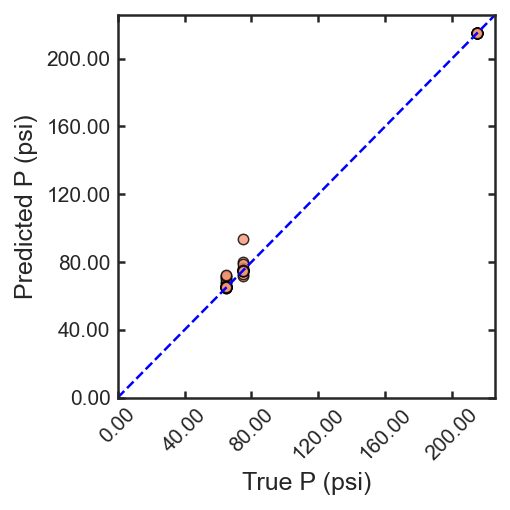

   -> figures\01_model_fit\Model_Fit_P_(psi).png
[Al]/[Ti]: R² = 0.9908 | MAPE = 0.53%


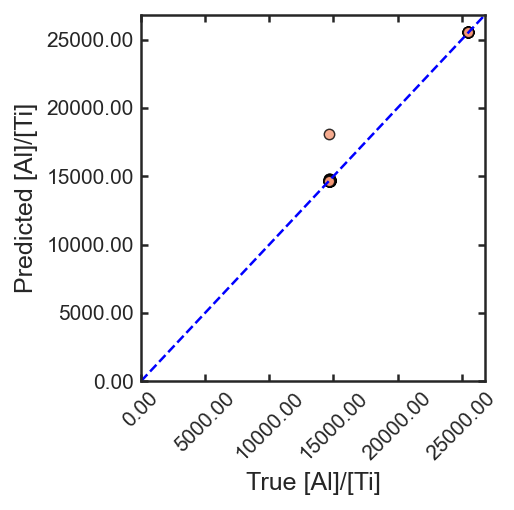

   -> figures\01_model_fit\Model_Fit_Al_Ti.png
C8 preload (g): R² = 0.9988 | MAPE = 2.91%


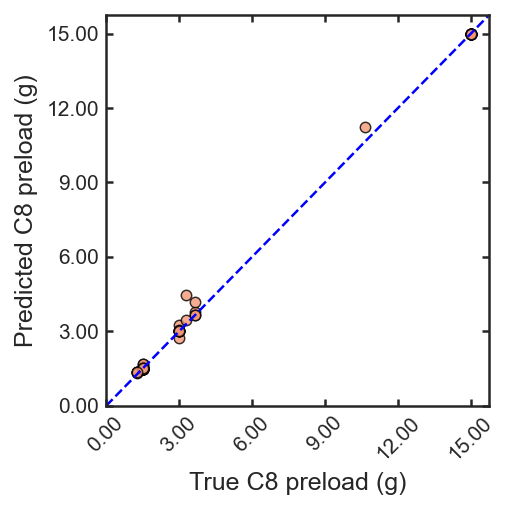

   -> figures\01_model_fit\Model_Fit_C8_preload_(g).png
Reaction time (min): R² = 0.9580 | MAPE = 3.41%


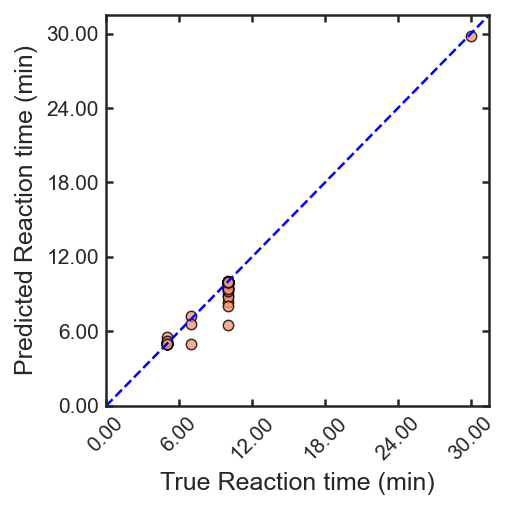

   -> figures\01_model_fit\Model_Fit_Reaction_time_(min).png


In [13]:
def plot_model_fit(model, df_test, targets, folder):
    y_true = df_test[targets]
    y_pred = pd.DataFrame(model.predict(df_test[FEATURES]), columns=targets, index=df_test.index)

    for target in targets:
        r2 = r2_score(y_true[target], y_pred[target])
        mape = mean_absolute_percentage_error(y_true[target], y_pred[target]) * 100
        print(f'{target}: R² = {r2:.4f} | MAPE = {mape:.2f}%')

        fig, ax = plt.subplots(figsize=FIG_SQUARE)
        ax.scatter(y_true[target], y_pred[target], alpha=0.8, color=COLOR_POINT,
                   s=25, edgecolor='black', linewidth=0.7)

        min_val = 0
        max_val = max(y_true[target].max(), y_pred[target].max()) * 1.05
        ax.plot([min_val, max_val], [min_val, max_val], 'b--', linewidth=1.2)

        format_axes(ax, f'True {target}', f'Predicted {target}', label_size=12, tick_size=10)
        ax.set_xlim(min_val, max_val)
        ax.set_ylim(min_val, max_val)

        save_figure(fig, folder, f'Model_Fit_{safe_name(target)}.png')


model = load_result(FILE_MODEL_S2)
df_test = load_result(FILE_TEST_REAL)
plot_model_fit(model, df_test, TARGETS, FIGURE_DIRS['model_fit'])

### 3.2 Target distributions: train vs. test
Proportion histograms. Two versions: real training half (no suffix) and augmented training set of Scenario 2 (suffix `_aug`). Folder: `figures/02_target_distributions/`

>>> Real training half vs. test half


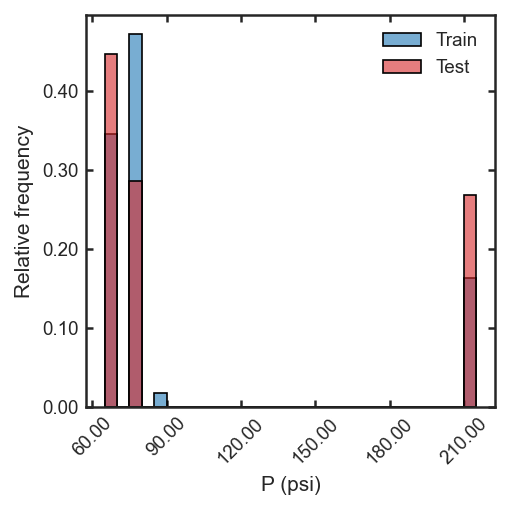

   -> figures\02_target_distributions\Distribution_P_(psi).png


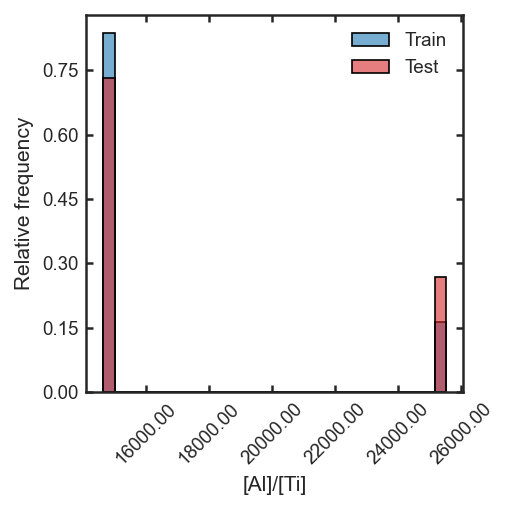

   -> figures\02_target_distributions\Distribution_Al_Ti.png


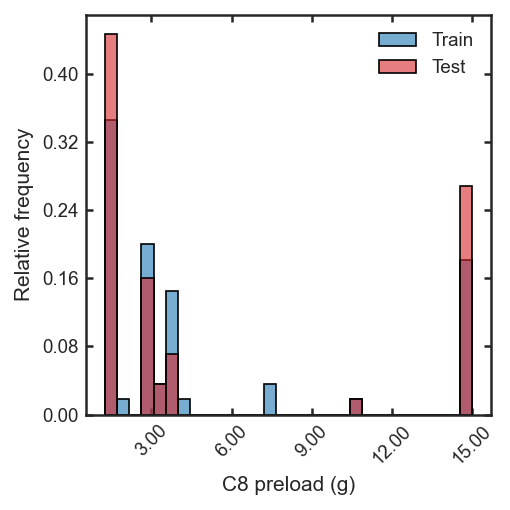

   -> figures\02_target_distributions\Distribution_C8_preload_(g).png


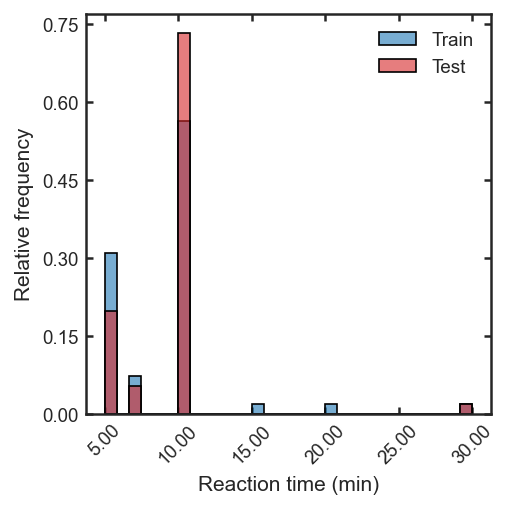

   -> figures\02_target_distributions\Distribution_Reaction_time_(min).png

>>> Augmented training set (Scenario 2) vs. test half


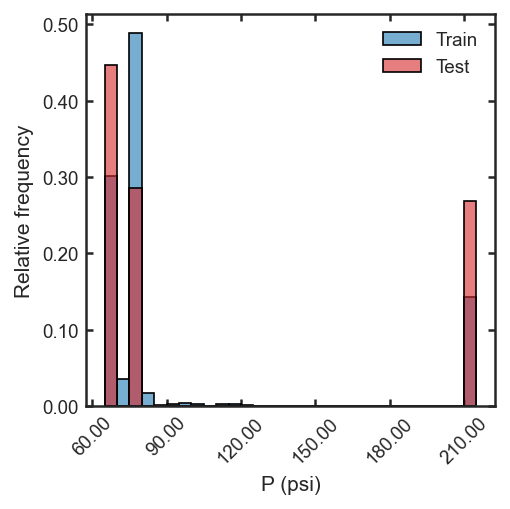

   -> figures\02_target_distributions\Distribution_P_(psi)_aug.png


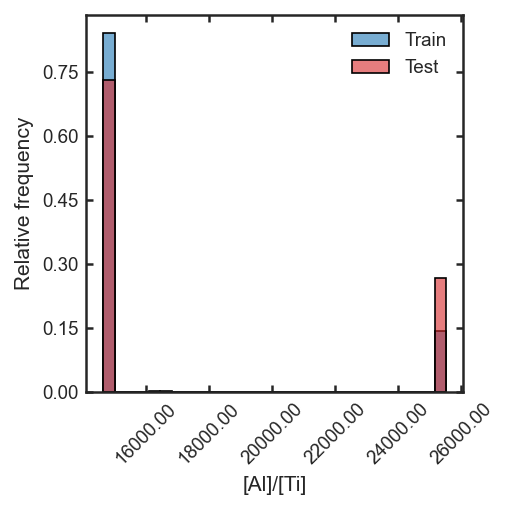

   -> figures\02_target_distributions\Distribution_Al_Ti_aug.png


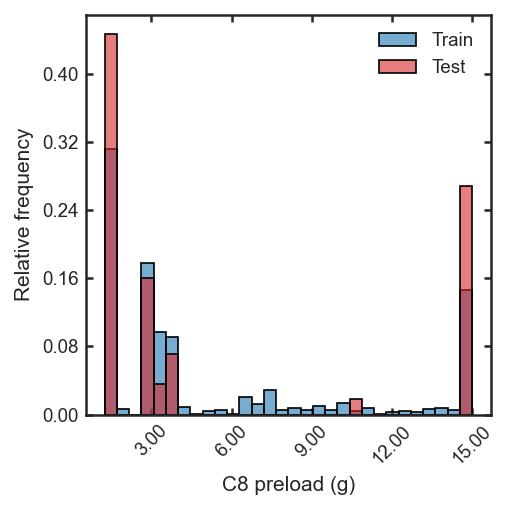

   -> figures\02_target_distributions\Distribution_C8_preload_(g)_aug.png


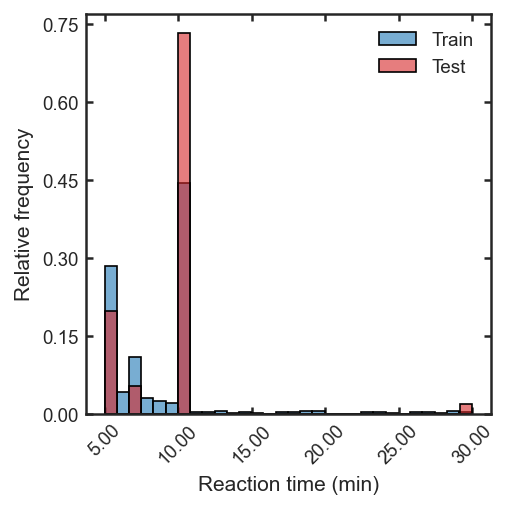

   -> figures\02_target_distributions\Distribution_Reaction_time_(min)_aug.png


In [21]:
def plot_target_histograms(df_train, df_test, targets, folder, suffix=''):
    for target in targets:
        fig, ax = plt.subplots(figsize=FIG_SQUARE)

        sns.histplot(df_train[target], ax=ax, color=COLOR_TRAIN, label='Train', stat='proportion',
                     bins=30, alpha=0.6, edgecolor='black', linewidth=0.8)
        sns.histplot(df_test[target], ax=ax, color=COLOR_TEST, label='Test', stat='proportion',
                     bins=30, alpha=0.6, edgecolor='black', linewidth=0.8)

        format_axes(ax, target, 'Relative frequency')
        ax.legend(frameon=False, loc='best', fontsize=9)

        save_figure(fig, folder, f'Distribution_{safe_name(target)}{suffix}.png')


df_train = load_result(FILE_TRAIN_REAL)
df_test  = load_result(FILE_TEST_REAL)
df_aug   = load_result(FILE_TRAIN_AUG_S2)
folder = FIGURE_DIRS['distributions']

print('>>> Real training half vs. test half')
plot_target_histograms(df_train, df_test, TARGETS, folder, suffix='')

print('\n>>> Augmented training set (Scenario 2) vs. test half')
plot_target_histograms(df_aug, df_test, TARGETS, folder, suffix='_aug')

### 3.3 Augmented data: original vs. augmented vs. test
`WF_Max` against each target, comparing the real training half, the augmented training set (Scenario 2) and the test half. Folder: `figures/03_augmented_data/`

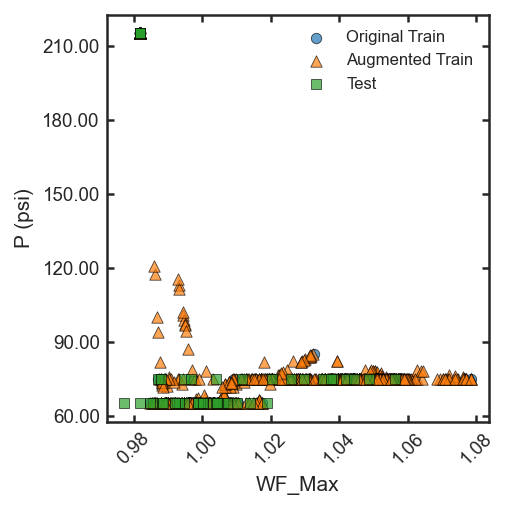

   -> figures\03_augmented_data\Scatter_WF_Max_vs_P_(psi).png


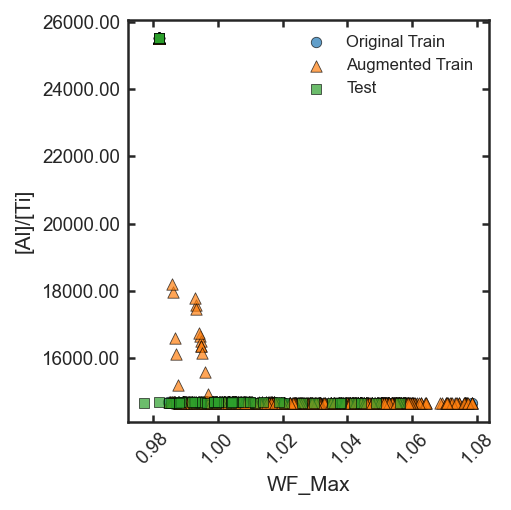

   -> figures\03_augmented_data\Scatter_WF_Max_vs_Al_Ti.png


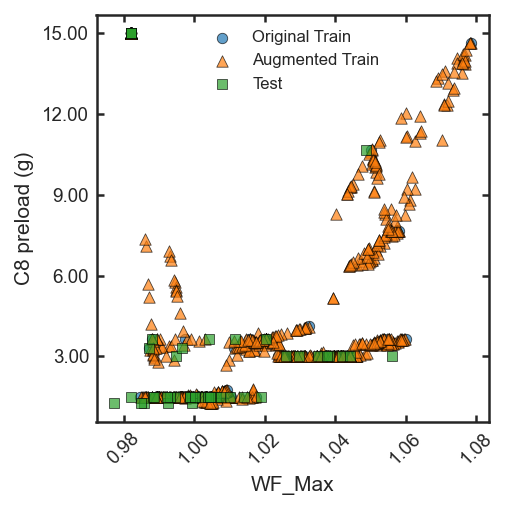

   -> figures\03_augmented_data\Scatter_WF_Max_vs_C8_preload_(g).png


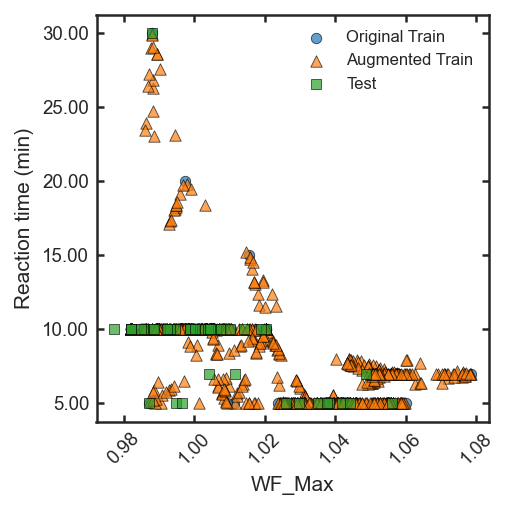

   -> figures\03_augmented_data\Scatter_WF_Max_vs_Reaction_time_(min).png


In [15]:
def plot_augmentation_comparison(df_train_real, df_augmented, df_test, target, feature, folder):
    fig, ax = plt.subplots(figsize=FIG_SQUARE)

    groups = [
        (df_train_real, '#1f77b4', 'Original Train',  'o', 25),
        (df_augmented,  '#ff7f0e', 'Augmented Train', '^', 30),
        (df_test,       '#2ca02c', 'Test',            's', 22),
    ]
    for df, color, label, marker, size in groups:
        ax.scatter(df[feature], df[target], color=color, label=label, marker=marker,
                   s=size, alpha=0.7, edgecolor='black', linewidth=0.4)

    format_axes(ax, feature, target)
    ax.legend(frameon=False, loc='best', fontsize=8)

    save_figure(fig, folder, f'Scatter_{feature}_vs_{safe_name(target)}.png')


df_train = load_result(FILE_TRAIN_REAL)
df_test  = load_result(FILE_TEST_REAL)
df_aug   = load_result(FILE_TRAIN_AUG_S2)
for target in TARGETS:
    plot_augmentation_comparison(df_train, df_aug, df_test, target, 'WF_Max', FIGURE_DIRS['augmented'])

### 3.4 Targets vs. microstructural descriptors
Each target against each descriptor (`LogM_Mean`, `WF_Max`, `SCB_Mean`) for all real runs, one figure per pair. Folder: `figures/04_targets_vs_microstructure/`


>>> P (psi)


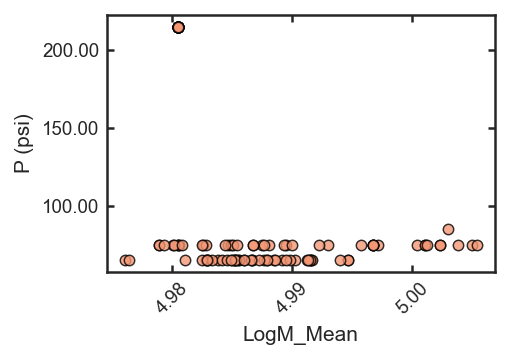

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_LogM_Mean_vs_P_(psi).png


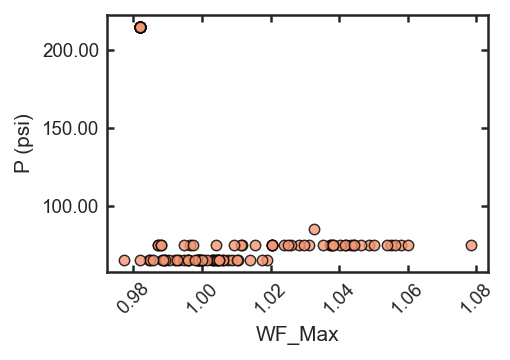

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_WF_Max_vs_P_(psi).png


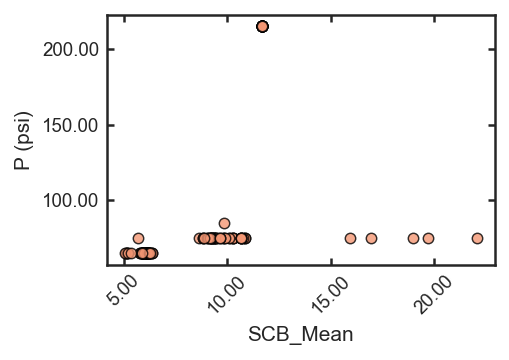

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_SCB_Mean_vs_P_(psi).png

>>> [Al]/[Ti]


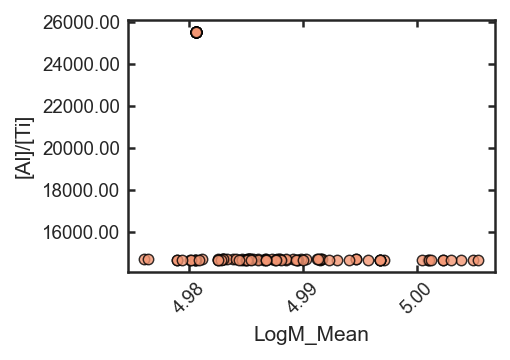

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_LogM_Mean_vs_Al_Ti.png


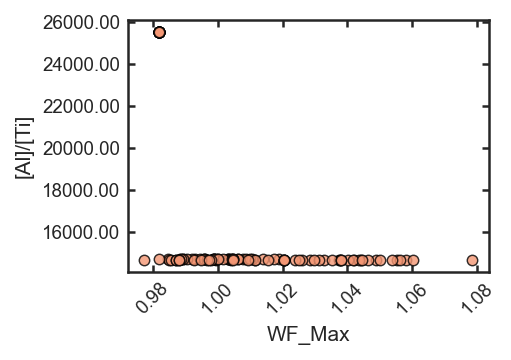

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_WF_Max_vs_Al_Ti.png


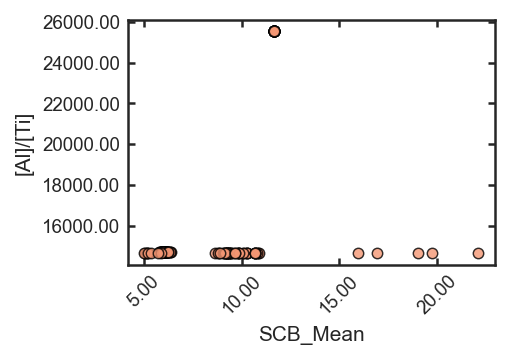

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_SCB_Mean_vs_Al_Ti.png

>>> C8 preload (g)


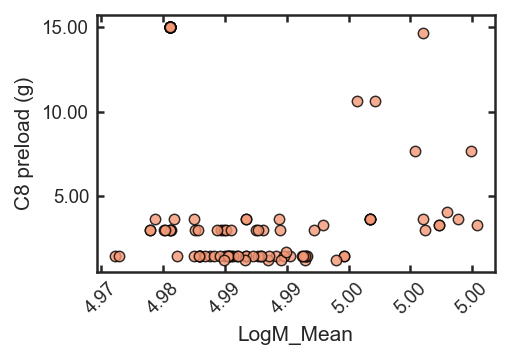

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_LogM_Mean_vs_C8_preload_(g).png


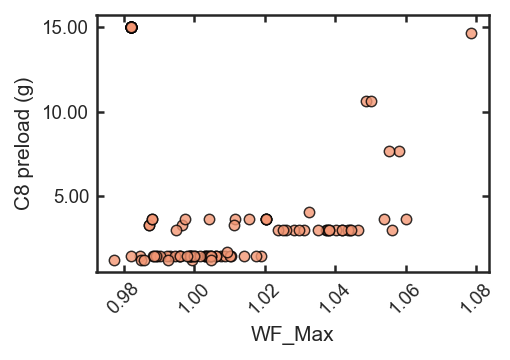

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_WF_Max_vs_C8_preload_(g).png


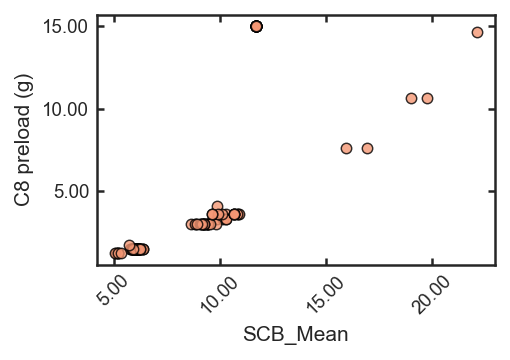

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_SCB_Mean_vs_C8_preload_(g).png

>>> Reaction time (min)


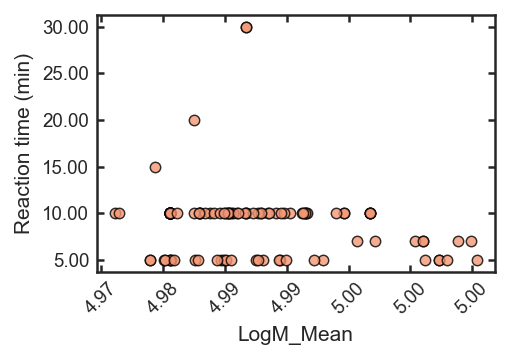

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_LogM_Mean_vs_Reaction_time_(min).png


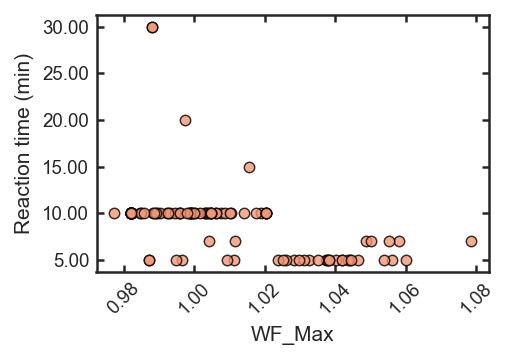

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_WF_Max_vs_Reaction_time_(min).png


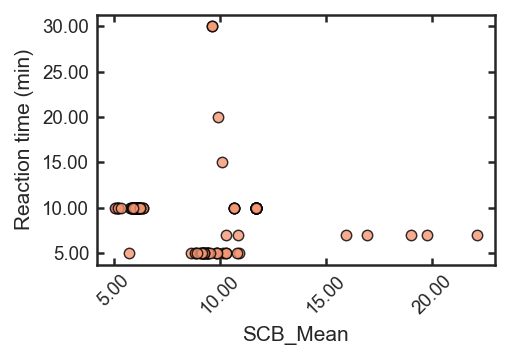

   -> figures\04_targets_vs_microstructure\Scatter_Indiv_SCB_Mean_vs_Reaction_time_(min).png


In [16]:
def plot_target_vs_microstructure(df, target, features, folder):
    for feature in features:
        fig, ax = plt.subplots(figsize=FIG_RECT)

        sns.scatterplot(data=df, x=feature, y=target, s=25, color=COLOR_POINT,
                        edgecolor='black', linewidth=0.7, alpha=0.8, ax=ax)

        format_axes(ax, feature, target, nbins=None)

        save_figure(fig, folder, f'Scatter_Indiv_{feature}_vs_{safe_name(target)}.png')


for target in TARGETS:
    print(f'\n>>> {target}')
    plot_target_vs_microstructure(df_full, target, FEATURES, FIGURE_DIRS['microstructure'])

### 3.5 GPC profiles: molecular weight distribution (dw/dLogM)
For each reactor condition: one figure with all ranges and one per range (same color for a range in both). Folder: `figures/05_gpc_mwd/`

In [17]:
SHOW_ON_SCREEN = False   # True to display the 16 figures here

df_gpc_plot = load_result(FILE_GPC_CLEAN)
folder = FIGURE_DIRS['gpc_mwd']

for target in TARGETS:
    df_gpc_plot, class_col, labels, colors = classify_gpc(df_gpc_plot, target)
    counts = df_gpc_plot[class_col].value_counts().reindex(labels)
    print(f'\n>>> {target}: ' + ' | '.join(f'{k} = {v}' for k, v in counts.items()))

    # All ranges together
    plot_gpc_profile(df_gpc_plot, GPC_WF, 'dw/dLogM', target, folder,
                     f'MWD_vs_Group_{safe_name(target)}.png', y_from_zero=True,
                     hue_col=class_col, palette=colors, show=SHOW_ON_SCREEN)

    # One figure per range
    for label in labels:
        df_class = df_gpc_plot[df_gpc_plot[class_col] == label]
        if df_class.empty:
            continue
        plot_gpc_profile(df_class, GPC_WF, 'dw/dLogM', target, folder,
                         f'MWD_Indiv_{safe_name(target)}_{safe_class_name(label)}.png',
                         y_from_zero=True, color=colors[label], label=label, show=SHOW_ON_SCREEN)


>>> P (psi): Low (<80) = 18329 | Medium (80-150) = 223 | High (>150) = 4454
   -> figures\05_gpc_mwd\MWD_vs_Group_P_(psi).png
   -> figures\05_gpc_mwd\MWD_Indiv_P_(psi)_Low_lt_80.png
   -> figures\05_gpc_mwd\MWD_Indiv_P_(psi)_Medium_80-150.png
   -> figures\05_gpc_mwd\MWD_Indiv_P_(psi)_High_gt_150.png

>>> [Al]/[Ti]: Low (<15k) = 18552 | Medium (15k-18k) = 446 | High (>18k) = 4008
   -> figures\05_gpc_mwd\MWD_vs_Group_Al_Ti.png
   -> figures\05_gpc_mwd\MWD_Indiv_Al_Ti_Low_lt_15k.png
   -> figures\05_gpc_mwd\MWD_Indiv_Al_Ti_Medium_15k-18k.png
   -> figures\05_gpc_mwd\MWD_Indiv_Al_Ti_High_gt_18k.png

>>> C8 preload (g): Low (<2.5) = 10440 | Medium (2.5-6) = 7002 | High (>6) = 5564
   -> figures\05_gpc_mwd\MWD_vs_Group_C8_preload_(g).png
   -> figures\05_gpc_mwd\MWD_Indiv_C8_preload_(g)_Low_lt_2.5.png
   -> figures\05_gpc_mwd\MWD_Indiv_C8_preload_(g)_Medium_2.5-6.png
   -> figures\05_gpc_mwd\MWD_Indiv_C8_preload_(g)_High_gt_6.png

>>> Reaction time (min): Short (<8) = 7435 | Medium (8-15

### 3.6 GPC profiles: short-chain branching (SCB / 1000 C)
Same as 3.5, for SCB. Folder: `figures/06_gpc_scb/`

In [18]:
SHOW_ON_SCREEN = False   # True to display the 16 figures here

df_gpc_plot = load_result(FILE_GPC_CLEAN)
folder = FIGURE_DIRS['gpc_scb']

for target in TARGETS:
    df_gpc_plot, class_col, labels, colors = classify_gpc(df_gpc_plot, target)
    print(f'\n>>> {target}')

    # All ranges together
    plot_gpc_profile(df_gpc_plot, GPC_SCB, GPC_SCB, target, folder,
                     f'SCB_vs_Group_{safe_name(target)}.png', y_from_zero=False,
                     hue_col=class_col, palette=colors, show=SHOW_ON_SCREEN)

    # One figure per range
    for label in labels:
        df_class = df_gpc_plot[df_gpc_plot[class_col] == label]
        if df_class.empty:
            continue
        plot_gpc_profile(df_class, GPC_SCB, GPC_SCB, target, folder,
                         f'SCB_Indiv_{safe_name(target)}_{safe_class_name(label)}.png',
                         y_from_zero=False, color=colors[label], label=label, show=SHOW_ON_SCREEN)


>>> P (psi)
   -> figures\06_gpc_scb\SCB_vs_Group_P_(psi).png
   -> figures\06_gpc_scb\SCB_Indiv_P_(psi)_Low_lt_80.png
   -> figures\06_gpc_scb\SCB_Indiv_P_(psi)_Medium_80-150.png
   -> figures\06_gpc_scb\SCB_Indiv_P_(psi)_High_gt_150.png

>>> [Al]/[Ti]
   -> figures\06_gpc_scb\SCB_vs_Group_Al_Ti.png
   -> figures\06_gpc_scb\SCB_Indiv_Al_Ti_Low_lt_15k.png
   -> figures\06_gpc_scb\SCB_Indiv_Al_Ti_Medium_15k-18k.png
   -> figures\06_gpc_scb\SCB_Indiv_Al_Ti_High_gt_18k.png

>>> C8 preload (g)
   -> figures\06_gpc_scb\SCB_vs_Group_C8_preload_(g).png
   -> figures\06_gpc_scb\SCB_Indiv_C8_preload_(g)_Low_lt_2.5.png
   -> figures\06_gpc_scb\SCB_Indiv_C8_preload_(g)_Medium_2.5-6.png
   -> figures\06_gpc_scb\SCB_Indiv_C8_preload_(g)_High_gt_6.png

>>> Reaction time (min)
   -> figures\06_gpc_scb\SCB_vs_Group_Reaction_time_(min).png
   -> figures\06_gpc_scb\SCB_Indiv_Reaction_time_(min)_Short_lt_8.png
   -> figures\06_gpc_scb\SCB_Indiv_Reaction_time_(min)_Medium_8-15.png
   -> figures\06_gpc_sc

### 3.7 Prediction intervals (bootstrap, 95%)
Test samples sorted by their true value: grey band = 95% prediction interval, line = prediction, dots = true values. Plain matplotlib, so every element can be edited. Folder: `figures/07_prediction_intervals/`

,Target,PICP (%),PINAW (%),MSE residuals (CV)
0,P (psi),91.07,7.26,1.64
1,[Al]/[Ti],98.21,7.77,11118.55
2,C8 preload (g),100.00,5.25,0.02
3,Reaction time (min),91.07,7.97,0.12


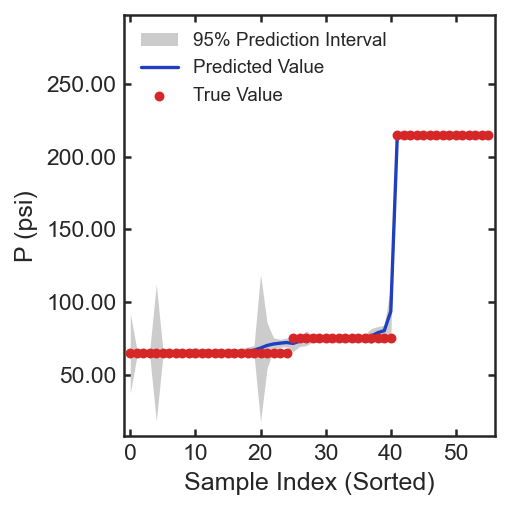

   -> figures\07_prediction_intervals\PI_Plot_P_(psi).png


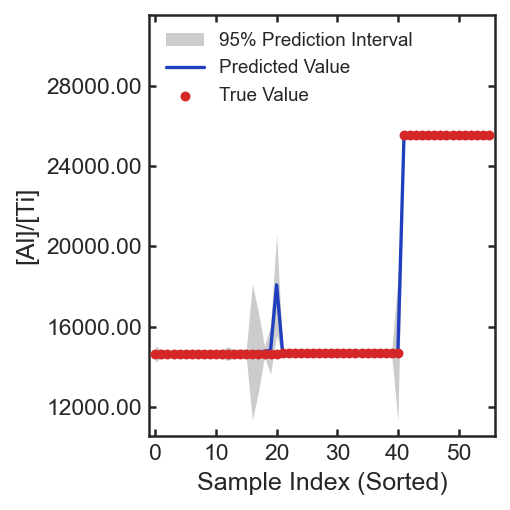

   -> figures\07_prediction_intervals\PI_Plot_Al_Ti.png


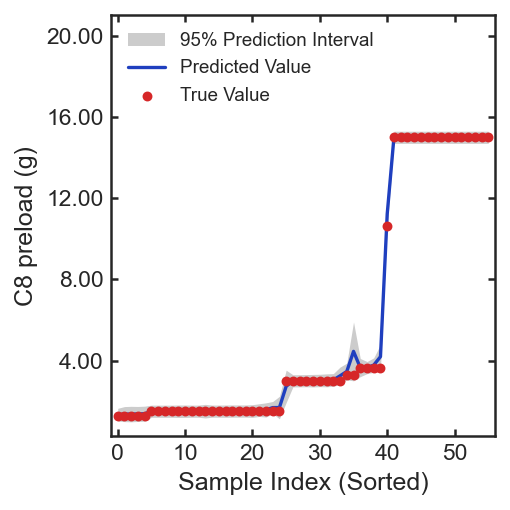

   -> figures\07_prediction_intervals\PI_Plot_C8_preload_(g).png


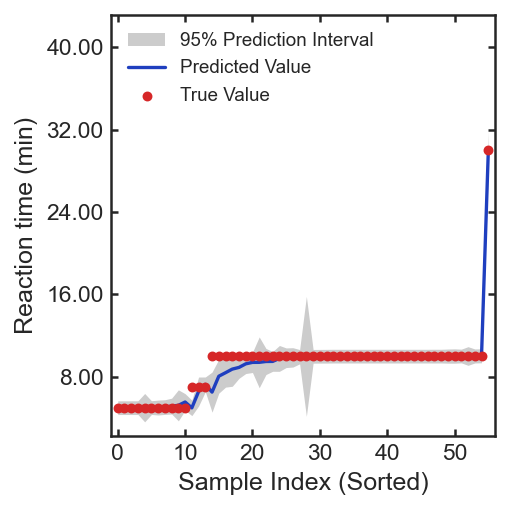

   -> figures\07_prediction_intervals\PI_Plot_Reaction_time_(min).png


In [22]:
# --- Appearance (edit here) ---
COLOR_INTERVAL  = '0.80'      # grey band
COLOR_PREDICTED = '#1f3fbf'   # blue line
COLOR_TRUE      = '#d62728'   # red dots
LABEL_SIZE      = 12          # axis titles
TICK_SIZE       = 11          # axis numbers
LEGEND_SIZE     = 9           # legend text
MARKER_SIZE     = 14          # red dots
LINE_WIDTH      = 1.6         # blue line
LEGEND_HEADROOM = 0.40        # extra space above the data for the legend (fraction of the y range)

def plot_prediction_intervals(df_pi, target, folder):
    d = (df_pi[df_pi['target'] == target]
         .sort_values(['y_true', 'y_pred'], kind='stable')
         .reset_index(drop=True))
    x = np.arange(len(d))

    fig, ax = plt.subplots(figsize=FIG_SQUARE)
    ax.fill_between(x, d['lower'], d['upper'], color=COLOR_INTERVAL, linewidth=0,
                    label='95% Prediction Interval')
    ax.plot(x, d['y_pred'], color=COLOR_PREDICTED, linewidth=LINE_WIDTH, label='Predicted Value')
    ax.scatter(x, d['y_true'], color=COLOR_TRUE, s=MARKER_SIZE, zorder=3, label='True Value')

    format_axes(ax, 'Sample Index (Sorted)', target, label_size=LABEL_SIZE, tick_size=TICK_SIZE,
                x_rotation=0, x_fmt='%d')
    ax.set_xlim(-1, len(d))

    # Leave room at the top so the legend does not cover the data
    y_low  = min(d['lower'].min(), d['y_true'].min())
    y_high = max(d['upper'].max(), d['y_true'].max())
    span = y_high - y_low
    ax.set_ylim(y_low - 0.05 * span, y_high + LEGEND_HEADROOM * span)
    ax.legend(frameon=False, loc='upper left', fontsize=LEGEND_SIZE)

    save_figure(fig, folder, f'PI_Plot_{safe_name(target)}.png')


df_pi = load_result(FILE_PI)
display(load_result(FILE_PI_METRICS).round(2))
for target in TARGETS:
    plot_prediction_intervals(df_pi, target, FIGURE_DIRS['intervals'])